# 03 — Reserving integration: valuation-date experiment (Phase 2b prototype)

Follows Lina's proposal (valuation-date features, cut-off transaction histories, evaluation against subsequent development) and Sarah's convention of a valuation date at **period 40**.

**Questions**
1. Which valuation-date features can be reconstructed from SPLICE? (all of Lina's list — see §2)
2. Does segmenting claims with clusters improve a paid Chain Ladder RBNS reserve, compared with an unsegmented CL, simple banding and random groups?
3. Do clusters of *open* claims at the valuation date separate their subsequent development?

**Design rules**
- Only claims reported by V; transactions cut at V; IBNR excluded (separate problem).
- Cluster labels used to segment a triangle are built from information **at notification**, so a label means the same thing in every notification cohort.
- Triangles by **notification period**, inflated paid. Factors from fewer than 5 rows set to 1 (applied to all methods).
- Hindsight (payments after V) is used only to evaluate.

The full backtest over V = 20…40 runs in `scripts/run_valuation_experiment.py`; this notebook shows the V = 40 case and reads the saved tables.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
from src.data.splice import load_splice, validate
from src.features.valuation import features_at_notification, features_at_valuation, future_payments
from src.features.clustering import fit_kmeans_clusters, silhouette_by_k
from src.models.chain_ladder import paid_triangle, chain_ladder, segmented_reserve, actual_future_by_row, reserve_errors
std = load_splice("complexity_5")
cov = load_splice("complexity_5_cov_regen", "_cov")   # regenerated with covariate labels (scripts/regenerate_splice_cov.R)
pd.DataFrame({"standard": validate(std), "covariates (regen)": validate(cov)})

,standard,covariates (regen)
n_claims,3663,3663
payment_count_matches,True,True
first_txn_at_notification,True,True
last_txn_at_settlement,True,True
final_cumpaid_equals_inflated_payments,True,True
covariates_present,False,True


## 1. The portfolio at V = 40

In [2]:
V = 40
def snapshot(p):
    fv = features_at_valuation(p, V); fut = future_payments(p, V)
    return pd.Series({"claims": len(p.claims), "reported by V": len(fv), "IBNR at V": len(p.claims) - len(fv),
                      "open at V": int(fv.is_open.sum()), "paid to date (m)": fv.paid_to_date.sum() / 1e6,
                      "case estimates (m)": fv.case_estimate.sum() / 1e6, "actual future RBNS (m)": fut.sum() / 1e6})
pd.DataFrame({"standard": snapshot(std), "covariates": snapshot(cov)}).round(1)

,standard,covariates
claims,3663.0,3663.0
reported by V,3462.0,3485.0
IBNR at V,201.0,178.0
open at V,821.0,769.0
paid to date (m),645.0,610.4
case estimates (m),252.5,282.0
actual future RBNS (m),386.5,413.7


## 2. Valuation-date features (Lina's list), cut off at V

All reconstructable. `case_estimate` is the outstanding case estimate after the last transaction at or before V; revisions exclude the initial estimate set at notification.

In [3]:
fv = features_at_valuation(std, V)
fv.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
notif_period,3462.0,21.13,10.85,1.00,12.00,21.00,30.00,40.00
notidel,3462.0,2.07,1.56,0.01,0.91,1.69,2.84,12.13
age_since_notification,3462.0,19.37,10.85,0.00,10.20,19.56,28.64,39.53
paid_to_date,3462.0,186298.26,233604.49,0.00,34818.41,119516.45,270343.19,3501947.34
n_payments_to_date,3462.0,4.39,3.08,0.00,2.00,4.00,5.00,28.00
time_since_last_payment,3462.0,11.87,9.88,0.00,2.58,9.87,19.40,37.65
case_estimate,3462.0,72924.58,207469.79,0.00,0.00,0.00,0.00,2867366.94
incurred_to_date,3462.0,259222.85,279744.97,54.30,69465.06,212950.80,338074.26,3501947.34
initial_case_estimate,3462.0,125857.89,159413.18,54.30,26811.98,59914.45,169555.34,1709388.49
n_revisions_to_date,3462.0,4.13,3.61,0.00,2.00,3.00,6.00,34.00


## 3. Segmented Chain Ladder at V = 40

Clusters use notification delay and the initial case estimate **relative to its notification period** (`initial_ce_rel`), which removes the inflation drift (§3b).

In [4]:
fn = features_at_notification(std, V)
act = actual_future_by_row(std, V)
rows = {"Unsegmented CL": reserve_errors(segmented_reserve(std, V), act)}
for k in (2, 3, 4):
    _, lab = fit_kmeans_clusters(fn, k, columns=["notidel", "initial_ce_rel"])
    rows[f"K-means k={k}"] = reserve_errors(segmented_reserve(std, V, lab), act)
pd.DataFrame(rows).T.assign(estimate=lambda d: d.estimate / 1e6, actual=lambda d: d.actual / 1e6).round(1)

,estimate,actual,total_error_pct,row_abs_error_pct
Unsegmented CL,522.0,386.5,35.0,42.1
K-means k=2,524.1,386.5,35.6,42.7
K-means k=3,518.1,386.5,34.0,41.1
K-means k=4,521.6,386.5,34.9,42.1


## 3b. Inflation drift in cluster membership

The nominal initial case estimate roughly doubles between early and late notification periods, so a partition on nominal amounts moves later claims into higher clusters. Dividing by the median of the same notification period removes most of the shift.

In [5]:
from src.features.clustering import fit_kmeans_clusters as fk
print(fn.groupby(pd.cut(fn.notif_period, [0, 10, 20, 30, 40])).initial_case_estimate.median().round(0))
_, nom = fk(fn, 3, columns=["notidel", "initial_case_estimate"]); _, rel = fk(fn, 3, columns=["notidel", "initial_ce_rel"])
late = fn.notif_period > 20
pd.concat({"nominal CE": pd.crosstab(late, nom, normalize="index"), "relative CE": pd.crosstab(late, rel, normalize="index")}, axis=1).rename(index={False: "periods 1-20", True: "periods 21-40"}).round(3)

notif_period
(0, 10]     40001.0
(10, 20]    51577.0
(20, 30]    63069.0
(30, 40]    87734.0
Name: initial_case_estimate, dtype: float64


nominal CE               relative CE              
col_0                  0      1      2           0      1      2
notif_period                                                    
periods 1-20       0.310  0.416  0.273       0.333  0.400  0.266
periods 21-40      0.211  0.401  0.388       0.328  0.367  0.305

## 4. Backtest over valuation dates (from the script)

In [6]:
bt = pd.read_csv(ROOT / "reports/tables/backtest_rbns_cl.csv")
sel = ["Unsegmented CL", "Case estimates", "K-means [notif]", "Ward [notif]", "K-means [notif+cov]", "Ward [notif+cov]",
       "Bands of initial case estimate", "Random groups (placebo, mean)", "Injury-severity groups (true covariate)"]
t = bt[bt.method.isin(sel) & bt.k.isin([0, 1, 3])].pivot_table(index=["portfolio", "method", "k"], columns="V", values="total_error_pct")
t["mean |error|"] = t.abs().mean(axis=1)
t.round(1)

V                                                       20    24    28    32    36    40  mean |error|
portfolio  method                                  k                                                  
covariates Bands of initial case estimate          3 -48.3  -8.8   3.9  27.0   5.1  27.8          20.2
           Case estimates                          0 -40.6 -39.7 -34.9 -34.8 -35.4 -31.8          36.2
           Injury-severity groups (true covariate) 3 -45.3 -10.4   1.7  29.9   4.9  14.1          17.7
           K-means [notif+cov]                     3 -46.4 -17.8  -1.7  27.7   1.2  11.9          17.8
           K-means [notif]                         3 -44.4  -7.2   1.4  29.3   7.9  29.7          20.0
           Random groups (placebo, mean)           3 -41.8 -12.0   3.3  32.6   6.0  20.5          19.4
           Unsegmented CL                          1 -46.2 -14.9   1.3  29.5   4.9  19.5          19.4
           Ward [notif+cov]                        3 -48.2 -13.2  -1.6  27.9   4.1  24.4          19.9
           Ward [notif]                            3 -44.5  -5.3   5.2  26.7   5.6  16.9          17.3
standard   Bands of initial case estimate          3 -56.3 -10.6   0.5  25.3  65.1  34.6          32.1
           Case estimates                          0 -45.0 -39.8 -33.5 -35.4 -36.2 -34.7          37.4
           K-means [notif]                         3 -57.6 -11.0   2.3  31.7  64.8  34.0          33.6
           Random groups (placebo, mean)           3 -56.1 -10.8   1.6  29.4  60.1  35.5          32.2
           Unsegmented CL                          1 -57.0 -12.6  -0.1  27.8  57.9  35.0          31.8
           Ward [notif]                            3 -57.8 -11.7  -0.4  21.9  55.8  35.3          30.5

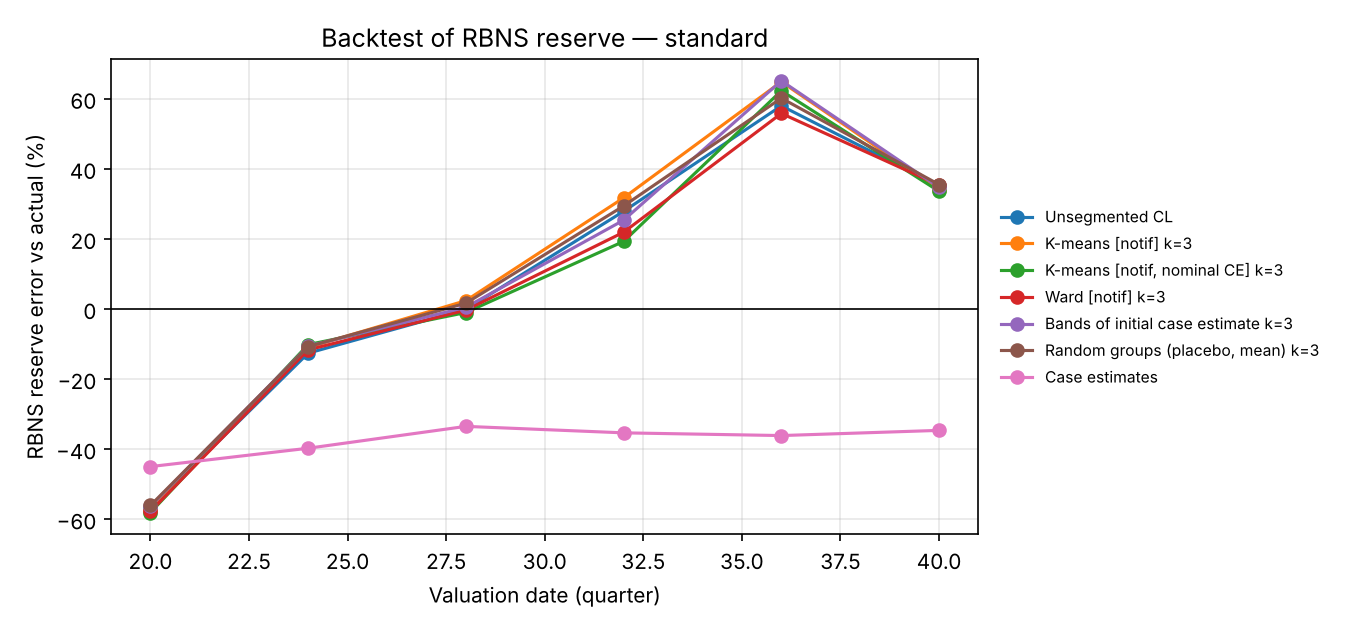

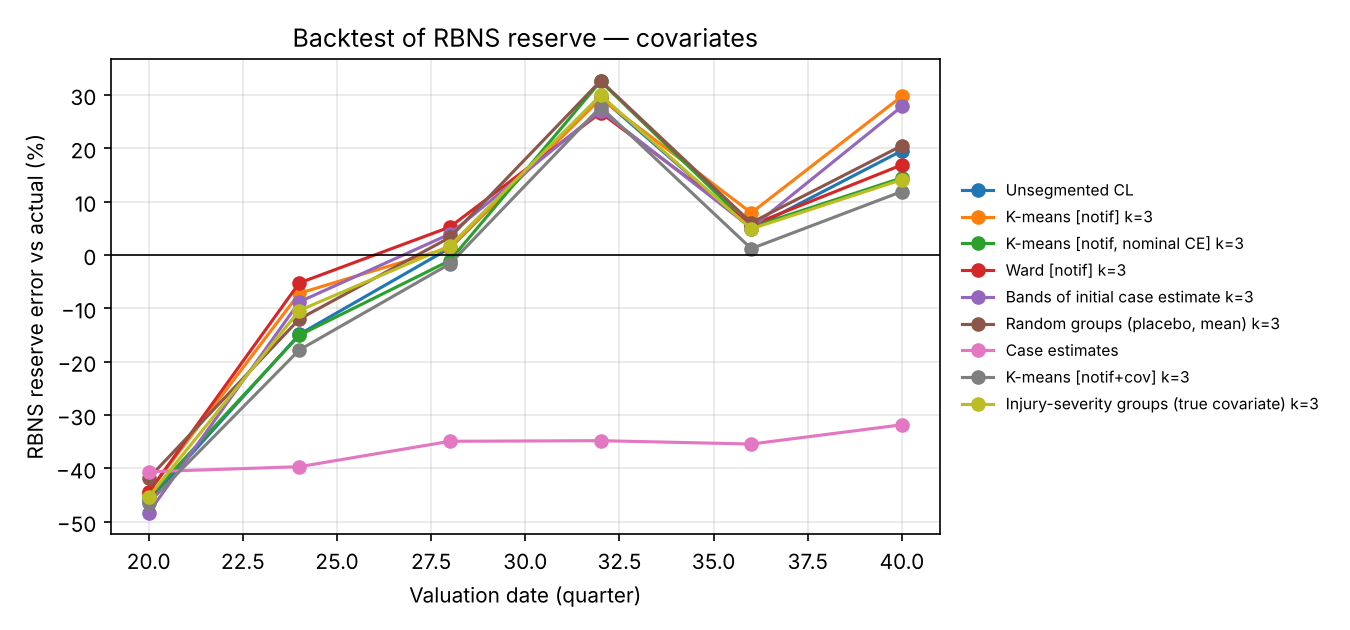

In [7]:
from IPython.display import Image, display
for n in ("standard", "covariates"):
    display(Image(str(ROOT / f"reports/figures/backtest_total_error_{n}.png")))

## 5. Open claims at V = 40: do clusters separate subsequent development?

In [8]:
pd.read_csv(ROOT / "reports/tables/open_claims_clusters_V40.csv").round(2)

,cluster,portfolio,n_open,median_age_since_notification,median_case_estimate,median_paid_to_date,case_estimate_m,actual_future_m,median_quarters_to_settle,actual_over_case_estimate
0,0,standard,264,1.91,95436.92,0.00,54.27,144.03,11.23,2.65
1,1,standard,308,7.86,270035.76,44574.59,89.71,133.03,5.79,1.48
2,2,standard,41,14.19,32528.89,337331.31,1.89,1.83,0.54,0.97
3,3,standard,208,12.52,413628.83,47687.61,106.60,107.66,4.82,1.01
4,0,covariates,14,4.57,242473.31,49154.61,3.19,3.54,3.16,1.11
5,1,covariates,284,1.85,144429.48,0.00,81.43,165.64,9.00,2.03
6,2,covariates,203,11.83,375793.55,58865.88,103.37,104.37,4.15,1.01
7,3,covariates,268,8.01,294139.65,51866.76,94.03,140.16,5.29,1.49


## 6. Out-of-time test: case-estimate factors by open-claim cluster

Groups and factors are fitted at V0 using data up to V1 = V0 + 8 only, applied unchanged at V1 and scored against the run-off after V1 (`scripts/run_open_claims_oot.py`, `src/models/case_estimate_factors.py`).

In [9]:
pd.read_csv(ROOT / "reports/tables/oot_summary.csv").round(2)

,portfolio,method,24,28,32,36,40,mean |error|,claim-level median |log error|
0,covariates,Bands of case estimate / initial (k=4),-1.83,1.87,-1.53,-10.80,-7.35,4.68,0.58
1,covariates,Bands of claim age (k=4),-0.14,-7.40,-5.49,-9.52,-3.63,5.24,0.55
2,covariates,K-means open-claim clusters (k=3),-1.38,-4.34,-5.46,-9.76,-2.12,4.61,0.61
3,covariates,K-means open-claim clusters (k=4),-1.66,-4.52,-4.97,-9.75,-2.12,4.60,0.63
4,covariates,K-means open-claim clusters (k=6),-3.15,-6.98,-8.66,-10.79,-2.32,6.38,0.57
5,covariates,K-means open-claim clusters + covariates (k=4),-1.64,-4.18,-5.02,-9.61,-2.10,4.51,0.61
6,covariates,Raw case estimates,-39.69,-34.93,-34.81,-35.44,-31.83,35.34,NaN
7,covariates,Single factor (no groups),3.05,-6.30,-4.58,-10.47,-6.32,6.14,0.50
8,covariates,Unsegmented paid CL (all reported claims),-14.89,1.29,29.55,4.91,19.53,14.03,NaN
9,standard,Bands of case estimate / initial (k=4),0.88,0.54,-0.12,-9.27,-6.79,3.52,0.64


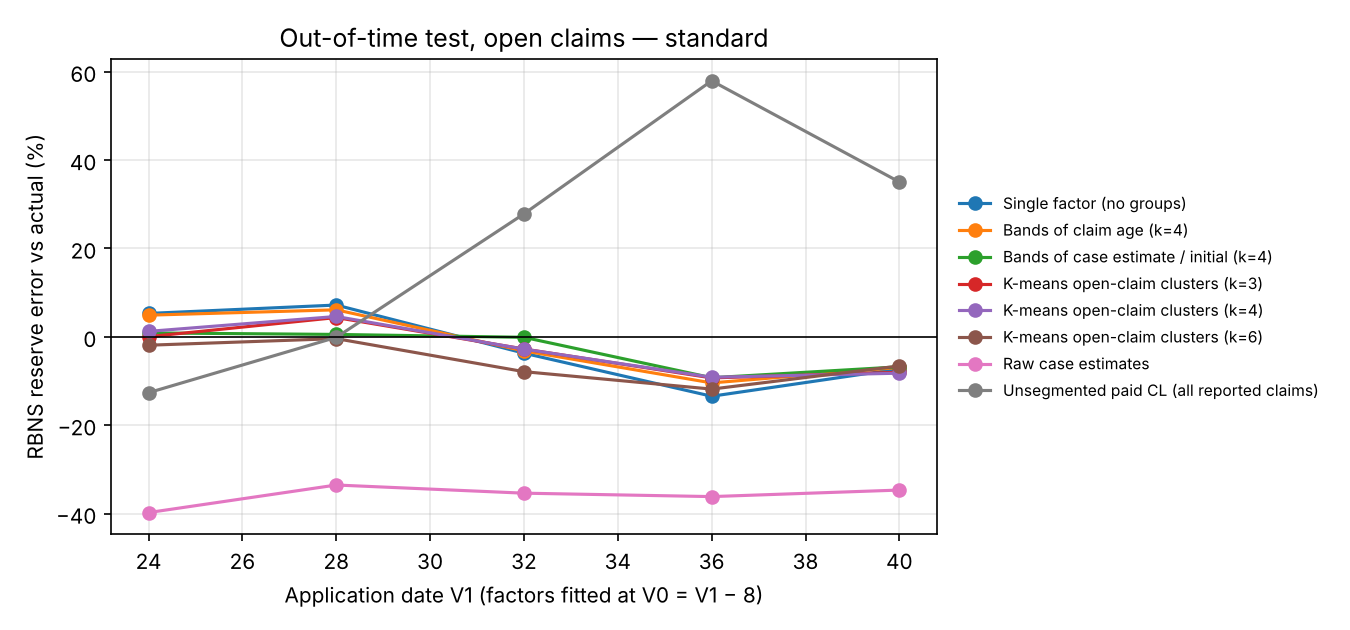

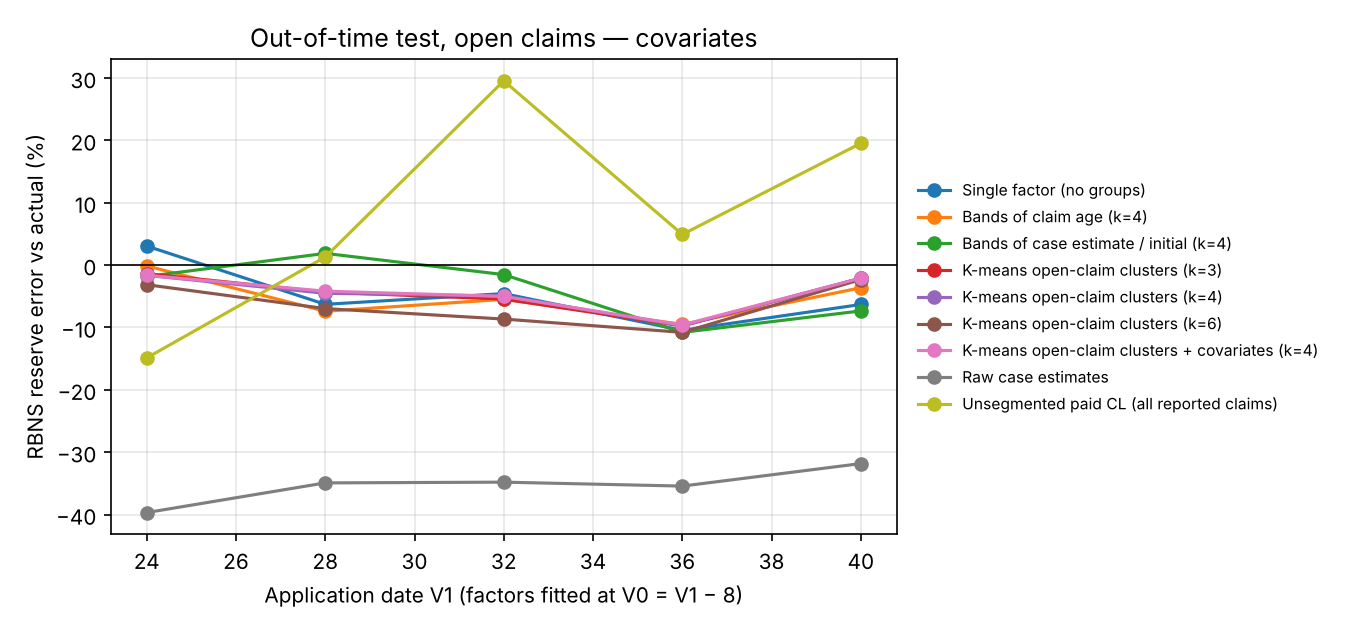

In [10]:
for n in ("standard", "covariates"):
    display(Image(str(ROOT / f"reports/figures/oot_open_claims_{n}.png")))

## 7. Reading the results

The full write-up is in `reports/phase_2b_valuation_date.md`. In short:

- **Segmenting the paid CL triangle** with notification-time clusters changes the RBNS error by a few points at most, which is within the range of random groups. The error is dominated by effects common to all segments: the trend in settlement speed, superimposed inflation and the tail.
- **Adjusting case estimates** with factors fitted 8 quarters earlier cuts the error from about −35% to about 5%, far better than paid CL. Most of the gain comes from a single factor. Open-claim clusters improve on the single factor by about 1.5–2.5 points, but simple bands of case estimate / initial estimate do as well.